In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.paths import FIG_DIR
import matplotlib.colors as mcolors
import numpy as np

from km5c.plotting import latdepthplot, shade_below_bathymetry
from km5c.models import load_cesm122

cesm122 = load_cesm122()
cesm122_Plio_d13C = cesm122.Plio_d13C
cesm122_Plio_depth = cesm122.Plio_depth
cesm122_Plio_lat = cesm122.Plio_lat
cesm122_Plio_lon = cesm122.Plio_lon
cesm122_preind_d13C = cesm122.preind_d13C
cesm122_preind_depth = cesm122.preind_depth
cesm122_preind_lat = cesm122.preind_lat
cesm122_preind_lon = cesm122.preind_lon

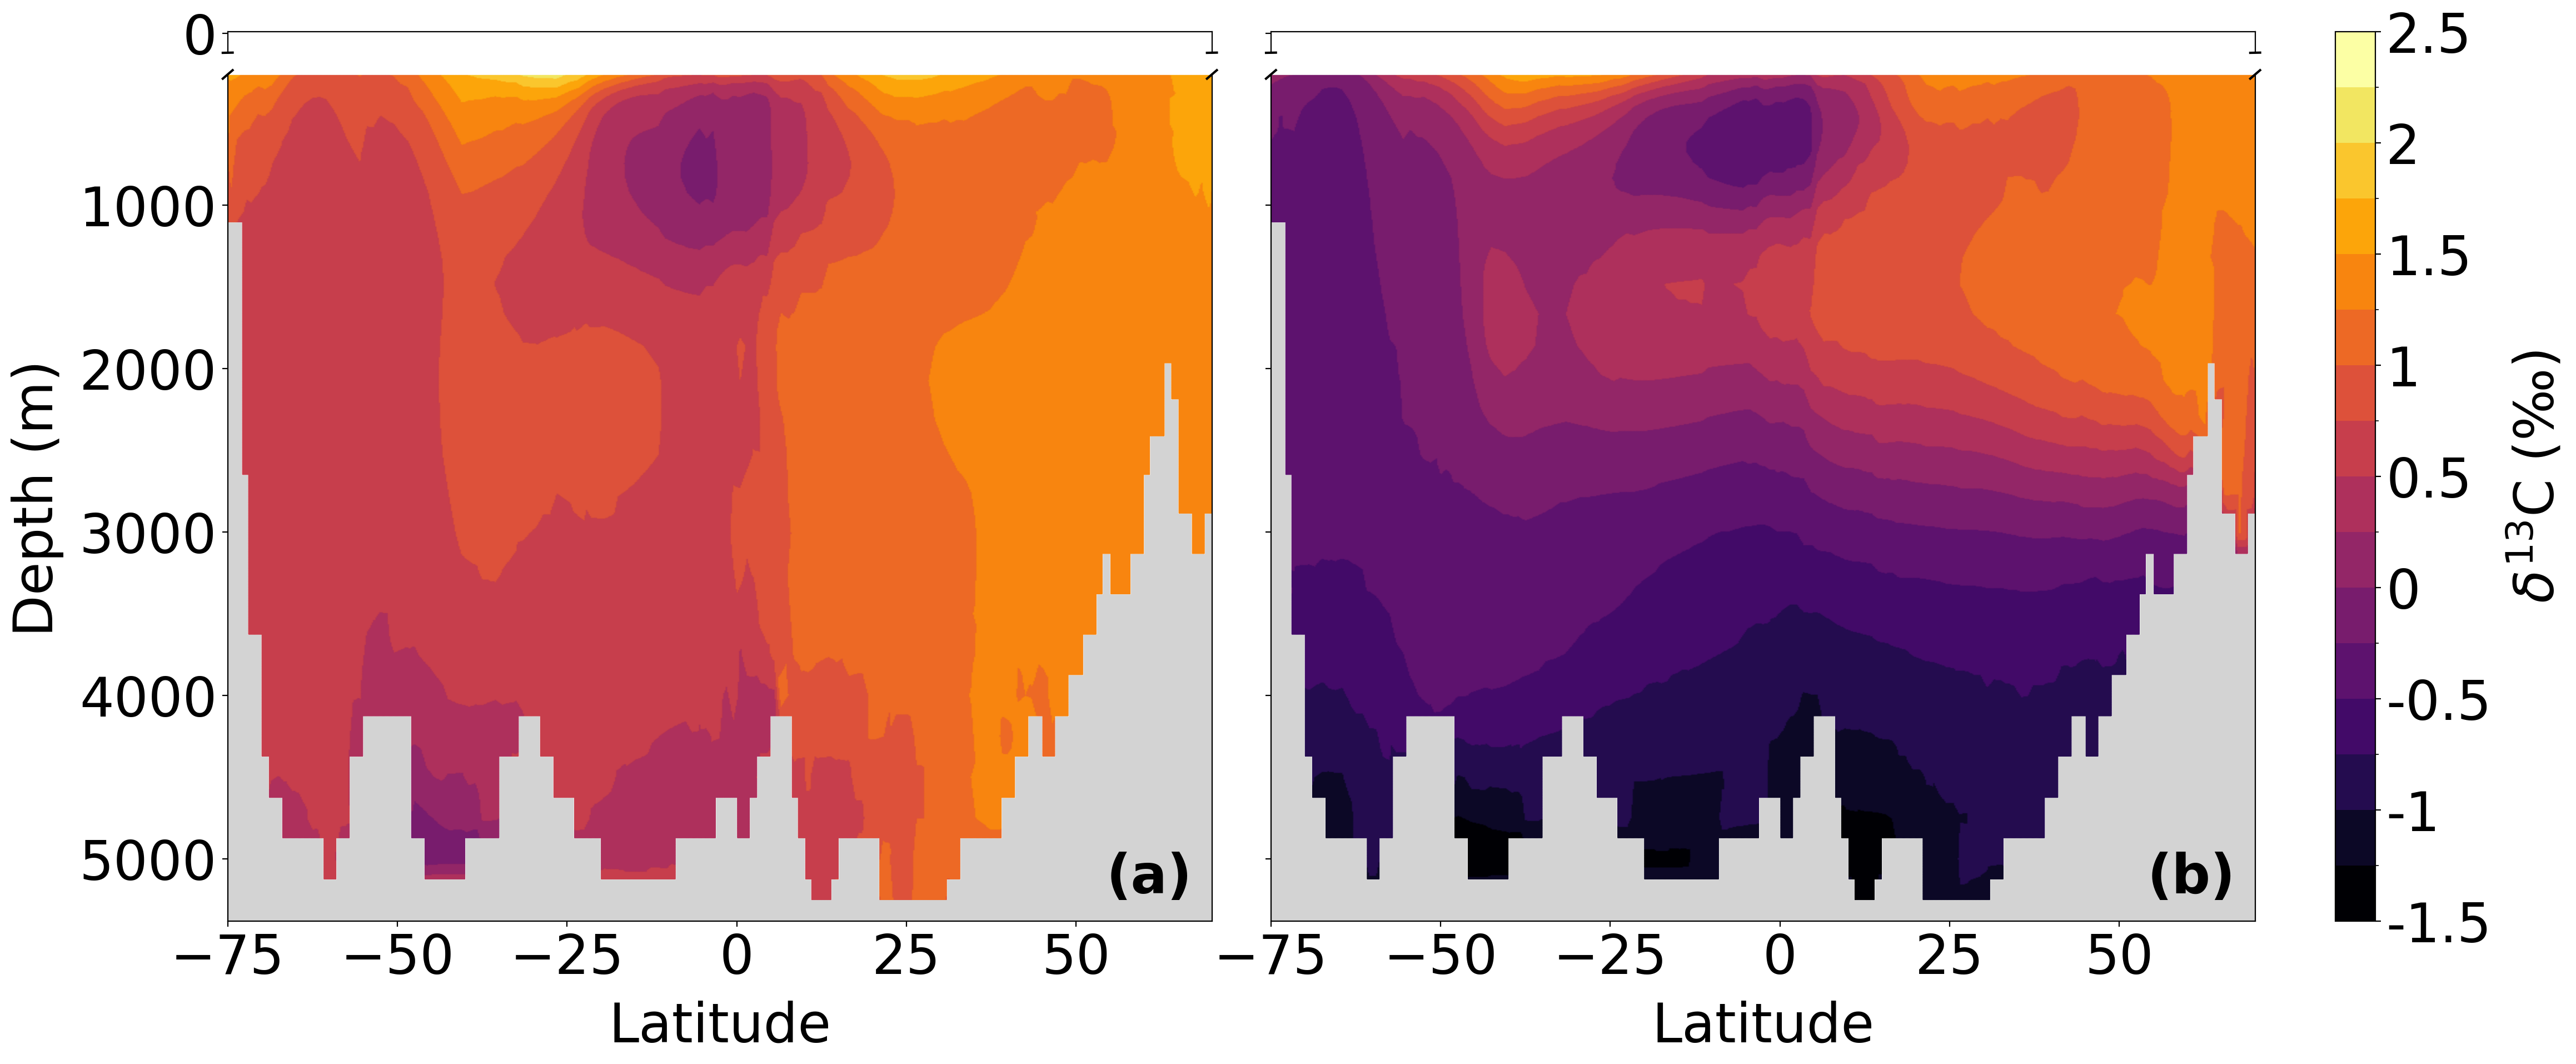

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(mpl.rcParamsDefault)
plt.rcdefaults()
mpl.rcParams.update({
    "font.size": 35,
    "axes.labelsize": 35,
    "xtick.labelsize": 35,
    "ytick.labelsize": 35,
})

color_bins = [-1.5, -1.25, -1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5]
num_colors = len(color_bins) - 1
colors = plt.cm.inferno(np.linspace(0, 1, num_colors))
cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(boundaries=color_bins, ncolors=num_colors)

panels = [
    {
        "lat": cesm122_preind_lat,
        "lon": cesm122_preind_lon,
        "depth_data": cesm122_preind_depth,
        "field": cesm122_preind_d13C,
        "scatter_col": "OC3 d13C",
        "label": "(a)",
    },
    {
        "lat": cesm122_Plio_lat,
        "lon": cesm122_Plio_lon,
        "depth_data": cesm122_Plio_depth,
        "field": cesm122_Plio_d13C,
        "scatter_col": "PLIOMIP2 d13C",
        "label": "(b)",
    },
]

fig = plt.figure(figsize=(24, 10), dpi=200)
# Leave more margin so axes are smaller than the full-width canvas;
# tick/label text then reads larger relative to the plotted area.
outer_grid = fig.add_gridspec(
    1, 2, wspace=0.06,
    left=0.10, right=0.86, top=0.94, bottom=0.14,
)

pc_for_cbar = None

for col, panel in enumerate(panels):
    testplot, lat, depth = latdepthplot(
        panel["lat"], panel["lon"], panel["depth_data"], panel["field"],
        trimtop=True, normalise=False, top=200,
        mask=None, mask_lat=None, mask_lon=None,
    )

    inner_grid = outer_grid[0, col].subgridspec(2, 1, height_ratios=[1, 40], hspace=0.05)
    ax1 = fig.add_subplot(inner_grid[0, 0])
    ax2 = fig.add_subplot(inner_grid[1, 0], sharex=ax1)

    shade_below_bathymetry(ax1, lat, depth, testplot)
    ax1.pcolormesh(lat, depth, testplot, cmap=cmap, norm=norm, shading='gouraud')
    ax1.set_ylim(-1, 10)
    ax1.set_xlim([-75, 70])
    ax1.set_yticks([0])
    ax1.tick_params(bottom=False, labelbottom=False)
    if col == 1:
        ax1.tick_params(labelleft=False)

    shade_below_bathymetry(ax2, lat, depth, testplot)
    pc_for_cbar = ax2.pcolormesh(lat, depth, testplot, cmap=cmap, norm=norm, shading='gouraud')
    ax2.set_ylim(200, 5380)
    ax2.set_xlim([-75, 70])
    ax2.set_xlabel('Latitude', labelpad=10)
    if col == 0:
        ax2.set_ylabel('Depth (m)', labelpad=10)
    else:
        ax2.tick_params(labelleft=False)

    ax1.invert_yaxis()
    ax2.invert_yaxis()

    ax1.spines['bottom'].set_visible(False)
    ax2.spines['top'].set_visible(False)

    
    d = 0.005
    kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
    ax1.plot((-d, +d), (-d, +d), **kwargs)
    ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    kwargs.update(transform=ax2.transAxes)
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

    ax2.text(
        0.98, 0.02, panel["label"],
        transform=ax2.transAxes,
        ha="right", va="bottom",
        fontsize=35, fontweight="bold",
        zorder=20,
    )

# Colour boundaries stay fine (0.25); label every other tick (0.5) to avoid clutter
cbar_ticks = color_bins[::2]
cbar_ax = fig.add_axes([0.89, 0.14, 0.015, 0.80])
cbar = plt.colorbar(pc_for_cbar, cax=cbar_ax, boundaries=color_bins, ticks=cbar_ticks)
cbar.set_ticklabels([f"{t:g}" for t in cbar_ticks])
cbar.set_label(r'$\delta^{13}\mathrm{C}$ (‰)', labelpad=10)

fig.savefig(FIG_DIR / "d13C_lat_depth.png", dpi=300, bbox_inches="tight")
plt.show()
